# KQC AirbridgeCrossings — airbridge crossings and a mechanical airbridge test array (Quantcore PDK rebuild)

**What the chip is.** **Source:** KQCircuits `chips/airbridge_crossings.py` (`AirbridgeCrossings`, default parameters, chip name "CTest"),
© IQM Finland Oy, GPL-3.0 (`other-libs/KQCircuits-main/.../kqcircuits/chips/airbridge_crossings.py`,
<https://github.com/iqm-finland/KQCircuits>). Spec: `docs/designs/kqc/test_chips.md` (row *AirbridgeCrossings*).

A process test chip. On the left a straight line PL-1 (NW → SW) and a line PL-3 (WN → WS) that weaves across it 20
times, each crossing an `AirbridgeConnection` that carries PL-3 over PL-1. On the right the same pair without
crossings: PL-2 straight (NE → SE) and PL-4 weaving between x = 7500 and 8000 µm (EN → ES). In the middle a
mechanical array: 19 bridge lengths × 8 widths × 4 distances = 608 short straight CPWs, with 5 default airbridges
across every second row (rows inside 1000 < y < 9000 µm only): 1280 bridges.

**Kept exactly (same KQC cells, parameters and positions):** the SMA8 launcher assignment
{1: PL-1-IN, 2: PL-2-IN, 3: PL-4-IN, 4: PL-4-OUT, 5: PL-2-OUT, 6: PL-1-OUT, 7: PL-3-OUT, 8: PL-3-IN}; the four
lines as Designer routes with KQC's nodes (`crossings = 10`, step = 4400 / 9.5 / 2 = 231.58 µm, wiggle 250 µm),
the 20 crossings as route waypoints with `airbridge=True` (KQC `Node(..., AirbridgeConnection)`); the 608 CPWs as
`WaveguideCoplanarStraight` cells of KQC's length 2 · 5 · (distance + width) + 4 µm centred on KQC's grid
(3600, 9650) + (400 j, −121 i − 2350 k); the 1280 `AirbridgeRectangular` cells (KQC's default `Airbridge`, no
parameters) at x offsets 50 · (n − 2) µm. KQC's commented-out per-element bridge length / width are not used by
KQC either, so all bridges are identical; only the CPW length varies. Step 14 XORs the chip with a stand-alone KQC build.

**Substituted:** the mechanical-test CPWs are `WaveguideCoplanarStraight` cells (KQC draws each as a two-point
`WaveguideCoplanar`, whose `path` a `design.json` cannot carry, and a route needs a port end). Same gap geometry;
KQC's `WaveguideCoplanar` adds a 5 µm (`margin`) end block to `ground_grid_avoidance` at each term-0 end that the
bare straight cell does not (step 14; KQC's grid is drawn here, so the grid may come up to 5 µm closer to those stub ends than in KQC).

**This rebuild on the Quantcore PDK** (not a replica; we distribute it under GPL-3.0):

| topic | KQC source | this rebuild (Quantcore PDK) |
|---|---|---|
| die | 10 × 10 mm, KQC `ChipFrame` | same 10 × 10 mm, Quantcore die frame (L dicing markers, 3 × 3 alignment grids, chip boundary, device ID "CTest") |
| launchers | SMA8, `launcher_indent` 800 µm (outer etch 20 µm from the edge) | SMA8, indent **880 µm** from the PDK pad rule (outer etch `frame.pad_edge` = 100 µm, 80 µm further in); same assignment |
| substrate | silicon (KQC simulation default) | sapphire 650 µm, εr 10.25 |
| junctions | none | none |
| cheese | KQC's whole-area ground grid (`with_grid`, in KQC's mask builds) | **the original wins:** KQC's grid (`with_grid=True`), so no PDK band |
| elements, positions, routes | — | kept: KQC's cells, parameters, positions and paths; waypoints from the launcher ports |
| placement | centred | centred (36 µm off in y, inside the 50 µm tolerance: no shift) |

The notebook walks through the build step by step: setup and the PDK → die and frame → launchers → components and
routes → DRC → netlist → LOM → FEM → results back → one design change → fab export → snapshots → summary. Steps
with nothing to act on say so.

## 1 · Setup

`LIVE` follows `QCC_LIVE` (default on: KLayout opens and redraws after every change; `QCC_LIVE=0` for batch
runs). `RUN_FEM = False` keeps the FEM step at "export only"; `True` solves the jobs in a new batch AEDT
2024 R1 (if installed). `FULL_FAB = False` skips the fab-only corner rounding in the fab step (the KQC grid has ≈ 0.9 M holes on 1/0 and 3/0) (`qcc mask` writes the full file).

In [2]:
%config InlineBackend.figure_formats = ["png"]
import math, os, sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)                                   # paths below are relative to the repo root
sys.path.insert(0, str(ROOT / "examples" / "designs"))
from _common import *                            # tables, snapshots, PDK and FEM step helpers
from quantcore_circuits.designer import Designer
from kqcircuits.pya_resolver import pya

LIVE = os.environ.get("QCC_LIVE", "1") == "1"   # live KLayout by default; QCC_LIVE=0 for batch runs
RUN_FEM = False                                  # True: solve the exported jobs in a new batch AEDT 2024 R1
FULL_FAB = False                                 # True: also round the corners in the fab export (slow here)
OUT = Path("examples/designs/kqc/test_chips")                 # design JSON + final snapshots
STEPS = Path("build/snapshots/airbridge_crossings")  # step-by-step snapshots (build/ is not kept in the repo)

## 2 · The PDK this chip uses

Every rule below comes from the PDK object (`get_pdk()`), not from this notebook: the stack feeds the LOM
estimates and the FEM exports, the frame and pad rule shape the die, the junction rule sizes the junctions,
and the cheese, 3/0 keep-out and corner-rounding rules apply when the mask is written.

This chip has no junctions; it uses the stack, the frame and pad rule, the cheese / 3/0 rules and the fab layer map.

In [3]:
display(Markdown(pdk_facts_md()))

| PDK rule | value |
|---|---|
| process | `quantcore_nb_sapphire_v1` v3 |
| stack | sapphire 650 µm, εr 10.25, Nb film (λ_L 0.09 µm) |
| CPW default | centre 10 µm, gap 6 µm, bend radius 100 µm |
| die frame | standard die 7.5 × 7.5 mm; L dicing markers (1000/0, 25 µm wide), 3 × 3 alignment grids (1001/0) in 500 µm corner areas, boundary 100/0, device ID |
| pad rule | bond pads / launchers: outer etch edge **100 µm** (`frame.pad_edge`) from the die edge (`edge="auto"`) |
| junctions | Nb/AlOx/Nb trilayer, Nb Δ 1.4 meV, R_n 40–50 kΩ (nominal 45 kΩ = 0.5 × 0.6 µm), C_J 50 fF/µm²; fingers 2/0 + 4/0, spacer 50/0 (+ 51–53/0 dose gradient) |
| qubit band | f_q 4–8 GHz (outside: DRC design warning `pdk_fq`) |
| cheese | the original design's own if it has one, else the PDK band: 5 µm squares, 20 µm gaps, 3 rows around the 3/0 keep-outs (chip param `cheese`: auto / pdk / original) |
| 3/0 keep-out | filled second-metal etch: routes CPW footprint + 10 µm, components etch bbox + 24 µm (or the cell's own) |
| corner rounding | fab only: r = 0.25 × the shortest dimension, ≤ 10 µm |

## 3 · The die and its frame

`Designer(...)` starts the 10 × 10 mm chip with the chip name "CTest" (the device ID) and KQC's SMA8 launcher assignment for this chip (only the assigned pads are drawn). `with_grid=True`
asks for KQC's whole-area ground grid (the original's cheese): the PDK band is then not added. The frame is the PDK
default (L dicing markers 1000/0, 3 × 3 alignment grids 1001/0, boundary 100/0); KQC's own `ChipFrame` is not drawn.

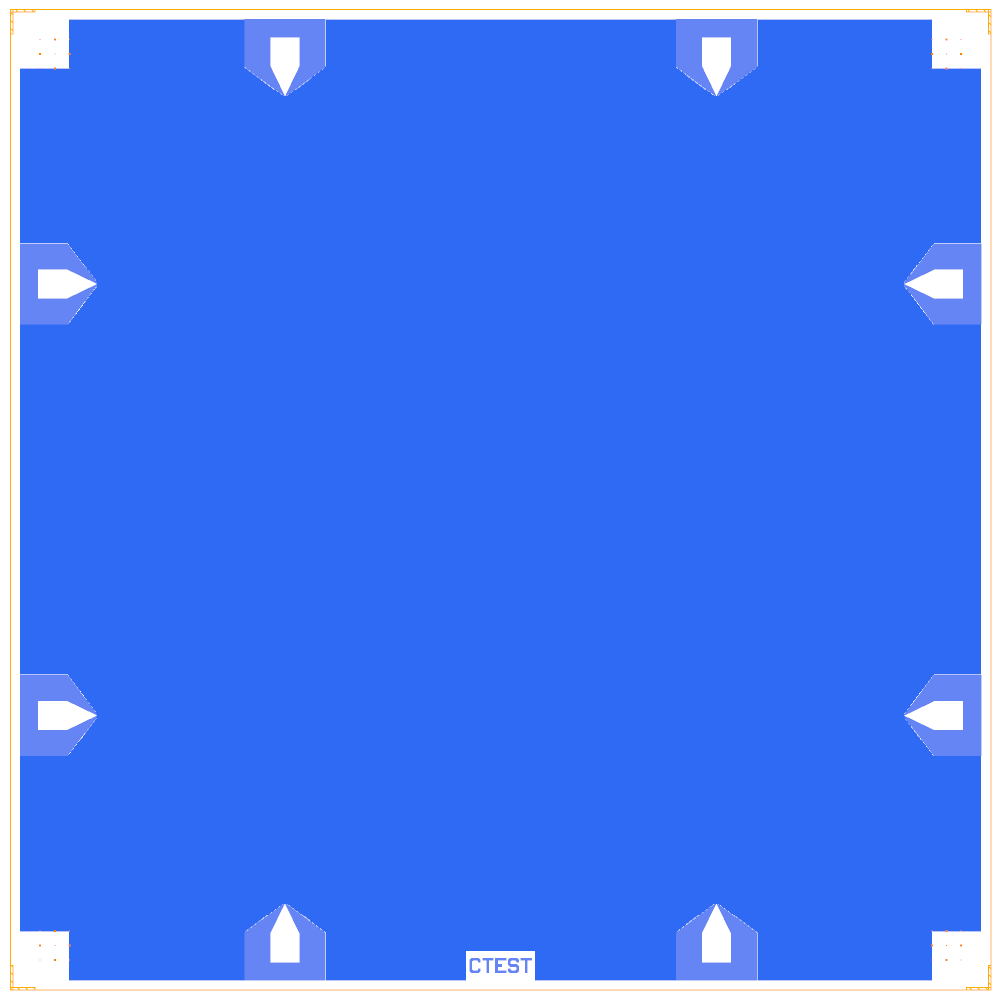

In [4]:
pads = {1: "PL-1-IN", 2: "PL-2-IN", 3: "PL-4-IN", 4: "PL-4-OUT", 5: "PL-2-OUT", 6: "PL-1-OUT", 7: "PL-3-OUT", 8: "PL-3-IN"}
d = Designer("airbridge_crossings", box=(0, 0, 10000, 10000), launchers={"type": "SMA8", "assign": pads},
             chip={"name_chip": "CTest", "with_grid": True}, live=LIVE)
snap(d, STEPS / "1_die.png", box=(-100, -100, 10100, 10100), size=(1000, 1000), width=420);

## 4 · Launchers and the pad rule

**PDK rule:** a launcher's outer etch edge sits `frame.pad_edge` (100 µm) from the die edge. For SMA8 (RF launcher:
300 µm taper + 300 µm pad + 180 µm frame gap) the Designer sets `launcher_indent` = 100 + 300 + 300 + 180 =
**880 µm** (KQC: 800 µm). Every line below starts at a launcher port or at a waypoint taken from one, so the 80 µm
shift needs no other change.

| pad | cell / launcher | nearest die edge | outer etch → die edge (µm) | PDK rule |
|---|---|---|---|---|
| chip.PL-1-IN | launcher port | n | port 880 µm in (indent from the rule) | ✓ |
| chip.PL-2-IN | launcher port | n | port 880 µm in (indent from the rule) | ✓ |
| chip.PL-4-IN | launcher port | e | port 880 µm in (indent from the rule) | ✓ |
| chip.PL-4-OUT | launcher port | e | port 880 µm in (indent from the rule) | ✓ |
| chip.PL-2-OUT | launcher port | s | port 880 µm in (indent from the rule) | ✓ |
| chip.PL-1-OUT | launcher port | s | port 880 µm in (indent from the rule) | ✓ |
| chip.PL-3-OUT | launcher port | w | port 880 µm in (indent from the rule) | ✓ |
| chip.PL-3-IN | launcher port | w | port 880 µm in (indent from the rule) | ✓ |

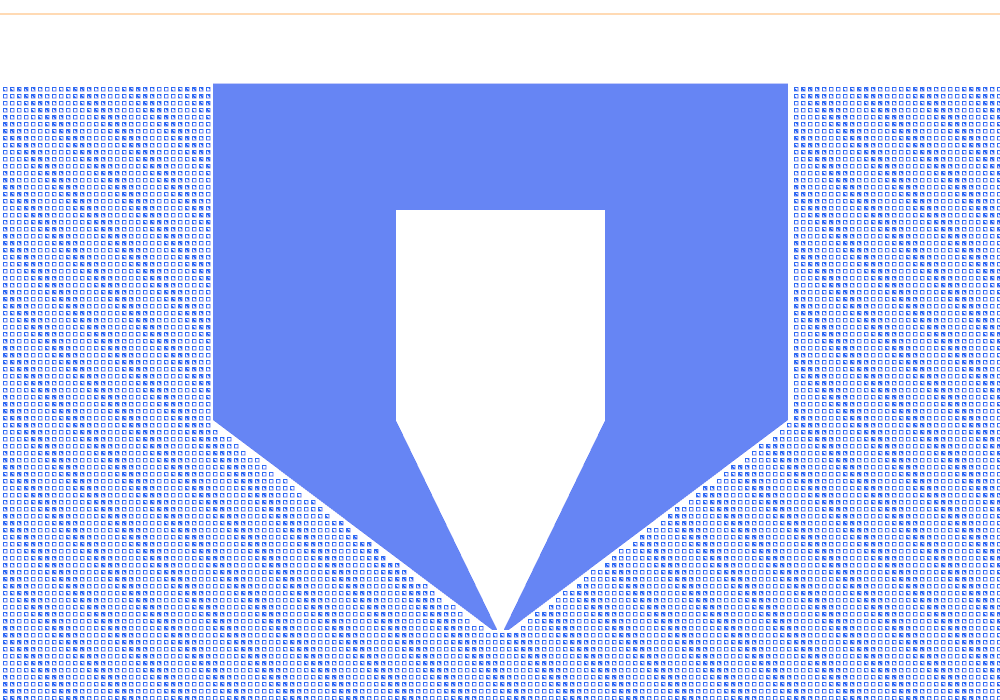

In [5]:
display(Markdown(pads_md(d)))
x, y = port_xy(d, "chip.PL-1-IN")
snap(d, STEPS / "2_launcher.png", box=(x - 400, y - 100, x + 400, 10000 + 20), size=(1000, 700), width=420);

## 5 · Components and 6 · Routes

The elements are placed in the order KQC places them, each on the ports of the previous ones, so components and routes are built together.

**The four lines and the mechanical array.** PL-1 and PL-2 run straight between their launchers; PL-3 weaves across PL-1 ten times each way, every crossing a waypoint with `airbridge=True` (KQC's `Node(..., AirbridgeConnection)`); PL-4 weaves the same way next to PL-2 without crossing. Then the 608 short CPWs of the mechanical array and the 1280 bridges across every second row inside 1000 < y < 9000 µm. This cell places 1892 instances, so it takes a while.

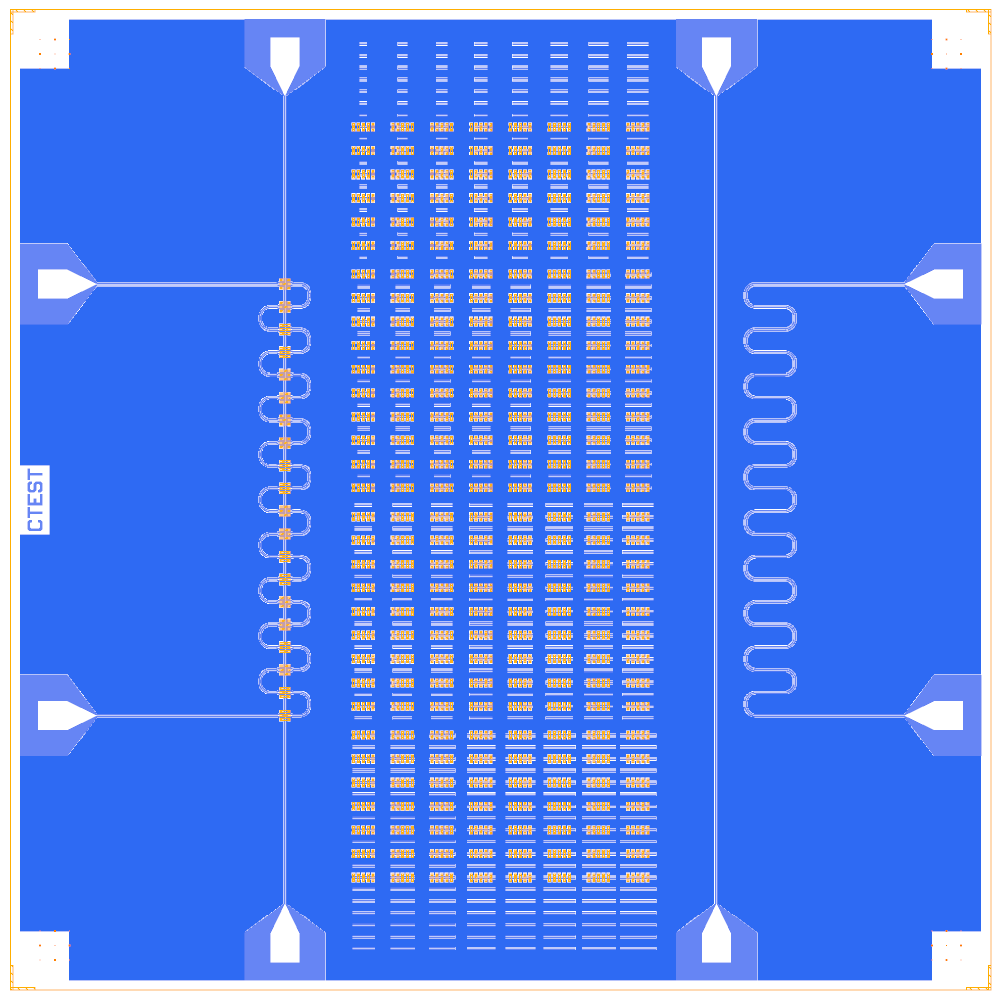

{'PL1': 8240.0, 'PL2': 8240.0, 'PL3': 16109.04, 'PL4': 15009.03}


In [6]:
W = d.waypoint
crossings, wiggle, b_number = 10, 250, 5            # KQC defaults (crossings = pairs of crossings)
x_pl1, _ = port_xy(d, "chip.PL-1-IN")
x_pl2, _ = port_xy(d, "chip.PL-2-IN")
_, y_in = port_xy(d, "chip.PL-3-IN")
_, y_out = port_xy(d, "chip.PL-3-OUT")
step = (y_in - y_out) / (crossings - 0.5) / 2
with d.batch():
    d.route("PL1", "chip.PL-1-IN", "chip.PL-1-OUT")      # straight, x = 2800
    d.route("PL2", "chip.PL-2-IN", "chip.PL-2-OUT")      # straight, x = 7200
    nodes, y = [], y_in                                  # PL-3 weaves across PL-1 on airbridges
    for _ in range(crossings):
        nodes += [(x_pl1 - wiggle, y), W((x_pl1, y), airbridge=True), (x_pl1 + wiggle, y)]
        y -= step
        nodes += [(x_pl1 + wiggle, y), W((x_pl1, y), airbridge=True), (x_pl1 - wiggle, y)]
        y -= step
    d.route("PL3", "chip.PL-3-IN", "chip.PL-3-OUT", nodes=nodes)
    nodes, y, xr = [], y_in, x_pl2 + 2 * wiggle + 50     # PL-4: the same weave, no crossing
    for _ in range(crossings):
        nodes += [(xr + wiggle, y), (xr - wiggle, y)]
        y -= step
        nodes += [(xr - wiggle, y), (xr + wiggle, y)]
        y -= step
    d.route("PL4", "chip.PL-4-IN", "chip.PL-4-OUT", nodes=nodes)

    # mechanical test array: CPW length from width and distance; bridges on every second row inside 1000 < y < 9000
    n_bridges = 0
    for i, length in enumerate(range(22, 60, 2)):
        for j, width in enumerate(range(5, 20, 2)):
            for k, distance in enumerate(range(2, 22, 5)):
                x, y = 3600 + 400 * j, 9650 - 121 * i - 2350 * k
                wg_len = 2 * b_number * (distance + width) + 4
                d.add(f"M{i}_{j}_{k}", "WaveguideCoplanarStraight", at=(x - wg_len / 2, y), l=wg_len)
                if (i + k) % 2 == 1 and 1000 < y < 9000:
                    for n in range(b_number):
                        d.add(f"AB{i}_{j}_{k}_{n}", "AirbridgeRectangular", at=(x + 50 * (n - (b_number - 1) / 2), y))
                        n_bridges += 1
snap(d, STEPS / "4_routes.png", box=(-100, -100, 10100, 10100), size=(1000, 1000), width=420)
print({k: round(v, 2) for k, v in d.result.route_lengths().items()})

**Centring, save.** No sim groups: through lines only (a transmission test is an S-parameter measurement, which `sim_tools` does not export). `center_in_die` checks that the content sits centred in the die and shifts it if it is more
than 50 µm off. Then the design is saved.

In [7]:
print("centring shift (µm):", center_in_die(d))
rebuild(d)
DESIGN = d.save(OUT / "airbridge_crossings.json")
print(d, "→", DESIGN)

centring shift (µm): (0.0, 0.0)
<Designer airbridge_crossings: 1888 instances, 4 routes, live=False> → examples\designs\kqc\test_chips\airbridge_crossings.json


## 7 · DRC

The DRC reports three kinds of issue. **Errors** (overlaps, crossings without a bridge, unconnected ends, metal
outside the die) make the build unfit for fab. **Warnings** are connectivity or geometry notes to read. **PDK
design warnings** flag values outside the PDK margins (`pad_edge`, `pdk_rn`, `pdk_fq`, `pdk_claw`): flagged,
never enforced — the rebuild keeps the source's choices. `pdk_report` adds the cheese source, the centring
and the junction types.

**Here:** 0 errors, 0 PDK design warnings and 7052 warnings, all on the mechanical array: 2560 `dangling_port` (both ports of each of the 1280 test bridges, which sit across a short CPW stub with both pads on the ground plane and join nothing) and 4492 `overlap` (bounding-box overlaps of those bridges with their own stub, the neighbouring rows' stubs and the bridges two rows away; KQC places them so). The routes are clean: PL-3 crosses PL-1 only on its 20 airbridge crossings, which the `crossing` rule accepts. `pdk_report` gives KQC's grid ("the original design's own"), the content 36 µm off in y and no junctions.

In [8]:
display(Markdown(drc_md(d.drc())))
display(Markdown(pdk_report(d)))

**0 errors · 7052 warnings · 0 PDK design warnings** (DRC clean)

| kind | rule | count | first message |
|---|---|---|---|
| warning | `dangling_port` | 2560 | AB0_0_1_0.a is not connected (no route or snap) |
| warning | `overlap` | 4492 | AB0_0_1_0 and AB2_0_1_0 overlap |

| check | value |
|---|---|
| cheese | the original design's own (or none) |
| content centre − die centre | (+0, +36) µm |
| junction types | — |
| PDK design warnings | 0 (none) |

## 8 · Netlist and LOM

`d.lom()` turns the layout into a lumped circuit from the components' LOM models: launchers are 50 Ω ports, a route
between two ports is one conductor (a through line), a route to a shorted end is a λ/4 resonator.

In [9]:
lb = d.lom()
summary = lom_summary(lb)
print(summary)
print("ports whose node is not in the circuit:",
      sum(1 for p, n in lb.port_map.items() if not n.startswith("control:") and n not in lb.model.nodes))
print(netlist_md(lb, max_notes=4).split("**Unconnected ports:**")[0])

{'nodes': 4, 'branches': 8, 'controls': 0, 'unconnected': 2560}
ports whose node is not in the circuit: 0
**5 nodes · 8 branches · 0 controls · 2560 unconnected ports**

| node | FEM nets |
|---|---|
| `gnd` | ground |
| `PL1` | `PL1`, `chip.PL-1-IN`, `chip.PL-1-OUT` |
| `PL2` | `PL2`, `chip.PL-2-IN`, `chip.PL-2-OUT` |
| `PL3` | `PL3`, `chip.PL-3-IN`, `chip.PL-3-OUT` |
| `PL4` | `PL4`, `chip.PL-4-IN`, `chip.PL-4-OUT` |

| branch | type | nodes | estimate |
|---|---|---|---|
| `Port_PL-1-IN` | R | `PL1` – `gnd` | 50 Ω |
| `Port_PL-1-OUT` | R | `PL1` – `gnd` | 50 Ω |
| `Port_PL-2-IN` | R | `PL2` – `gnd` | 50 Ω |
| `Port_PL-2-OUT` | R | `PL2` – `gnd` | 50 Ω |
| `Port_PL-3-IN` | R | `PL3` – `gnd` | 50 Ω |
| `Port_PL-3-OUT` | R | `PL3` – `gnd` | 50 Ω |
| `Port_PL-4-IN` | R | `PL4` – `gnd` | 50 Ω |
| `Port_PL-4-OUT` | R | `PL4` – `gnd` | 50 Ω |




## 9 · LOM simulation — not applicable

None: no junctions or resonators (four 50 Ω through lines). What the chip measures, the transmission across the crossings and the PL-1 ↔ PL-3 crosstalk, needs a driven FEM solve (step 10).

## 10 · FEM: send the jobs

One job per sim group and analysis: the group is cut out of the chip with its margin, every line leaving the
box ends in a port, junctions are lumped ports, and the ground grid is removed (simulation exports never have
cheese). The table lists each job's ports and C-matrix nets (named after islands, couplers and routes, so the
result maps back onto the LOM nodes).

With `RUN_FEM = True` and AEDT 2024 R1 (or later) installed, `send_fem_jobs` solves each Ansys job in a **new
batch, non-graphical** AEDT (`solve_job`) — an AEDT window you have open is never touched. The command-line
equivalent is `qcc sim run build/jobs/<job>` (or `qcc sim submit` to the Linux server).

Here: nothing to export: the chip has no sim groups.

In [10]:
jobs = send_fem_jobs(DESIGN, run=RUN_FEM)
display(Markdown(jobs_md(jobs) if jobs else "No sim groups: no FEM job."))

0 job(s) exported; RUN_FEM is False, nothing solved.


No sim groups: no FEM job.

## 11 · Bring the results back

When a job has been solved its folder holds `results/results.json`. `fem_back` then calls
`fill(model, design, job)`: the C-matrix (or eigenmode) values replace the component estimates branch by
branch (matched by net name), and the table compares the two. `simulate(filled)` re-runs the LOM on the
extracted values. Until then the cell says which jobs are still waiting.

In [11]:
filled, md = fem_back(lb.model, DESIGN, jobs)
display(Markdown(md or "No FEM jobs."))
if filled:
    from quantcore_circuits.lom.simulate import simulate
    key, fc = next(iter(filled.items()))
    display(Markdown(f"**LOM on the FEM values ({key}):**\n\n" + modes_md(simulate(fc, max_modes=2))))

No FEM jobs.

## 12 · Change one property — not applicable

There is no LOM simulation to re-run on this chip (through lines only), so this step has nothing to change and re-simulate.

## 13 · Build and export

**The design file.** `airbridge_crossings.json` (saved in step 6) is the whole design: `qcc build
examples/designs/kqc/test_chips/airbridge_crossings.json` rebuilds `build/airbridge_crossings.oas` + its sidecar, and the KLayout plugin,
`qcc watch` and the dashboard read it.

**The fab mask.** `export_fab` writes only the PDK fab layers: base etch 1/0 (with the cheese), the filled 3/0 keep-out (CPW footprint + 10 µm, components' etch bbox + 24 µm; 3/0 also holds every cheese
hole), airbridges 300/0 (pads) and 301/0 (bridges),
and the frame (100/0, 1000/0, 1001/0). The cheese source is `build`: KQC's grid drawn in the build (`with_grid=True`) stands, and no PDK band is added. In this run: 1/0 807 806 polygons, 3/0 766 969, airbridges 2680 pads (300/0) and 1340 bridges (301/0: the 1280 test bridges plus 3 per crossing); cheese source `build`, 806 561 holes. Corner rounding (fab only) is skipped unless `FULL_FAB`;
`qcc mask examples/designs/kqc/test_chips/airbridge_crossings.json` writes the complete file.

In [12]:
display(Markdown(fab_layers_md(d, cheese=True, rounding=FULL_FAB)))

| fab layer | PDK name | polygons |
|---|---|---|
| 1/0 | M1 | 807806 |
| 3/0 | M3 | 766969 |
| 100/0 | CHIP_BOUNDARY | 1 |
| 300/0 | AIRBRIDGE_PADS | 2680 |
| 301/0 | AIRBRIDGE_BRIDGE | 1340 |
| 1000/0 | MARKERS_DICING | 4 |
| 1001/0 | MARKERS_ALIGN | 36 |

**Cheese:** source `build`, 806561 holes on the mask.

→ `build/airbridge_crossings_fab.oas`

## 14 · Snapshots

The snapshots of the source notebook (full chip and its zooms; the die frame's south-west corner, dicing L on
1000/0 and the 3 × 3 alignment grid on 1001/0) and one PL-3 crossing over PL-1 in the **fab view** (the mask from step 13: 1/0
and 3/0 with the grid holes). KQC's grid fills the ground as one tone at full-chip scale; the chip boundary 100/0
is drawn as an outline.

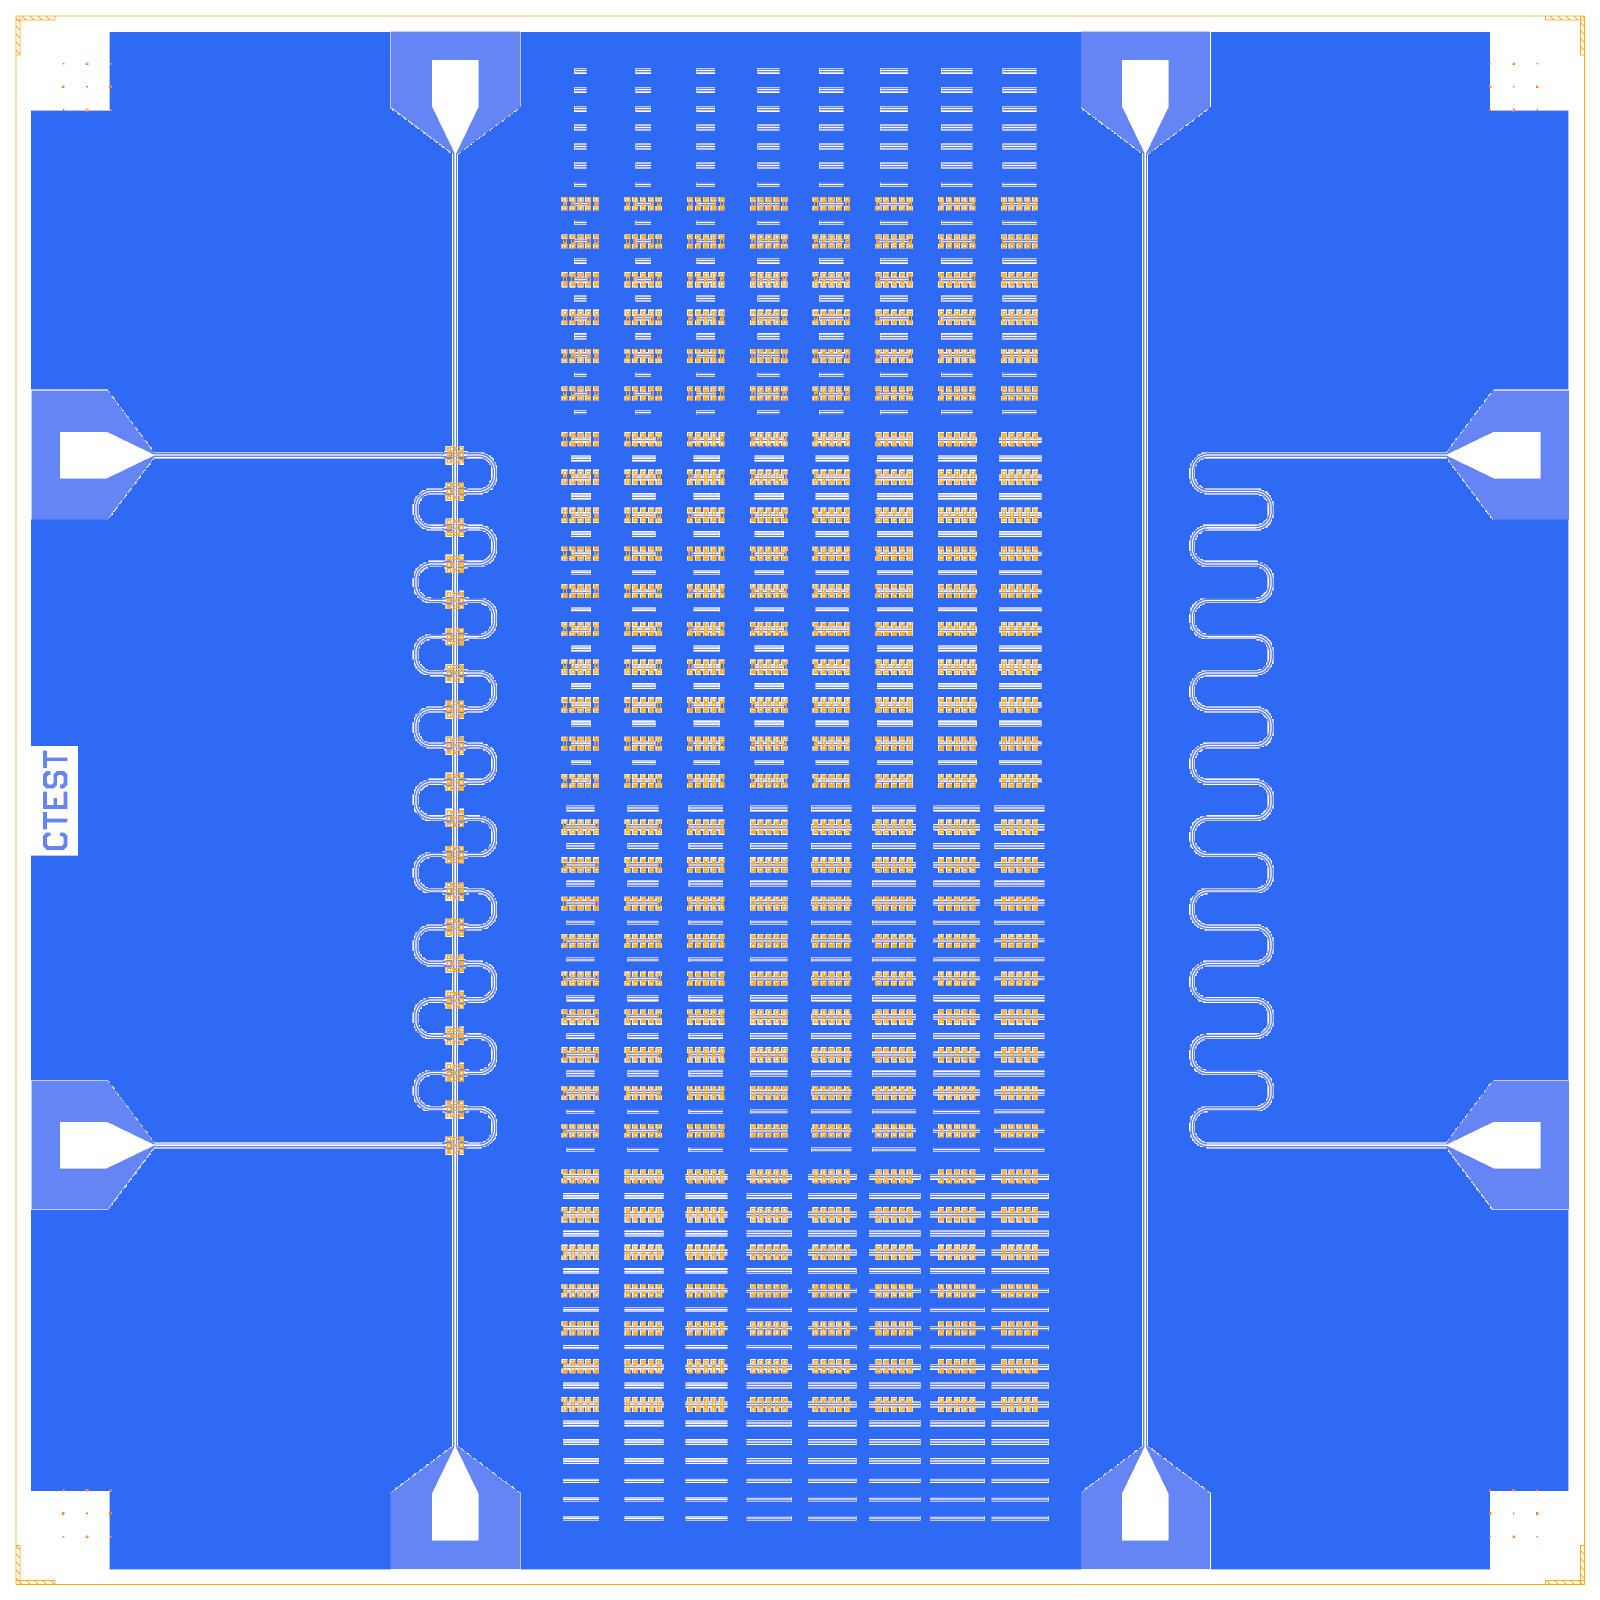

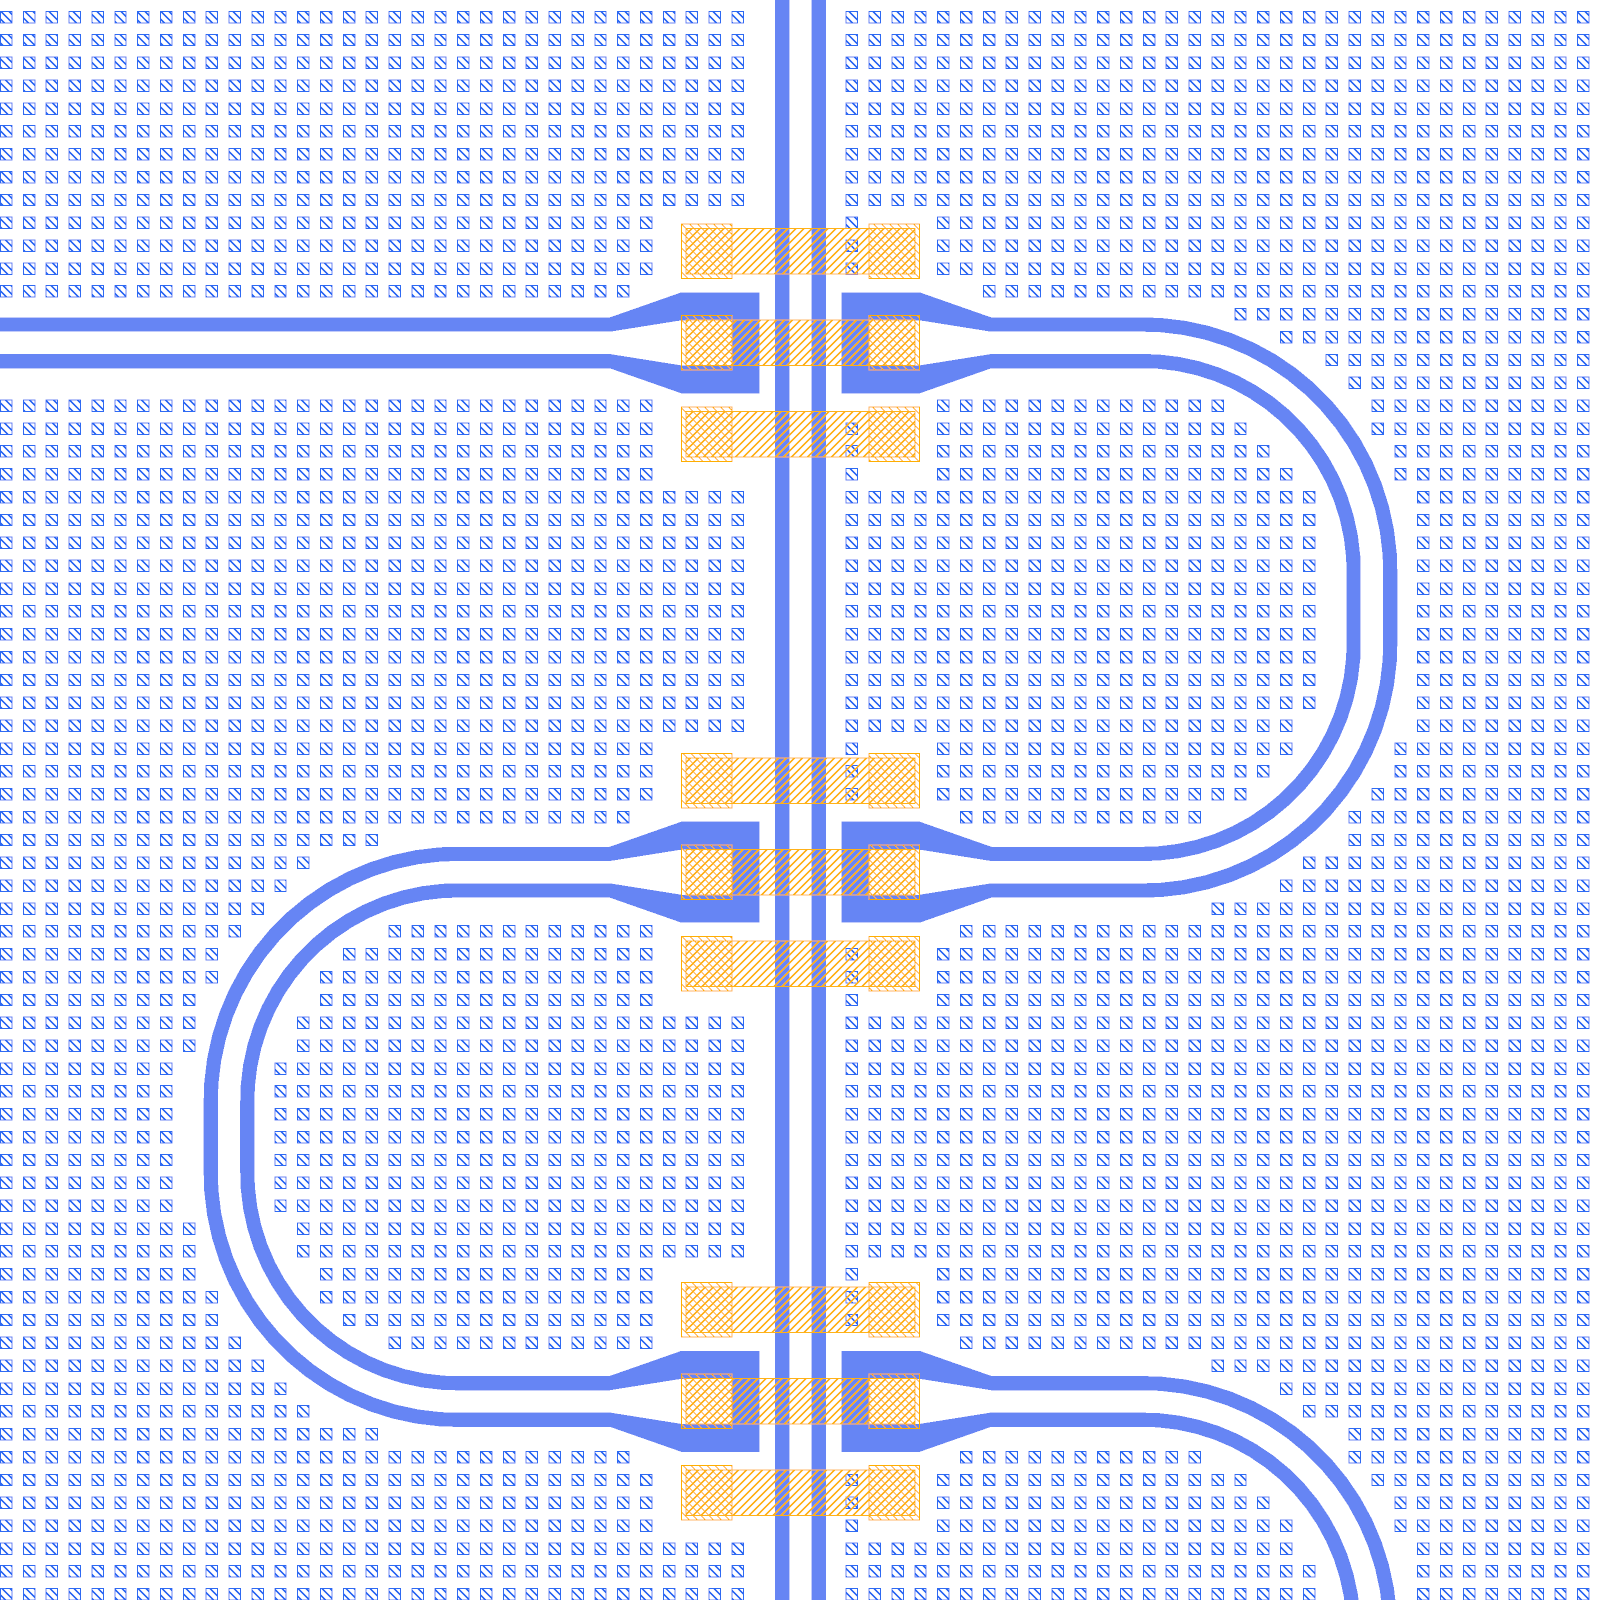

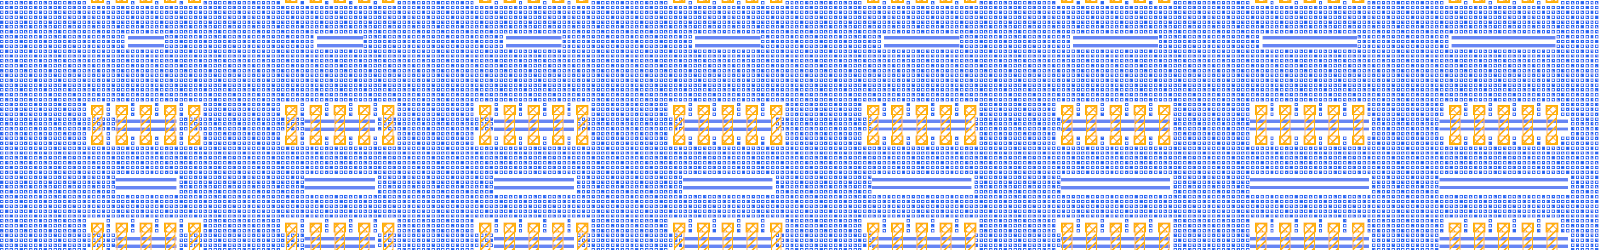

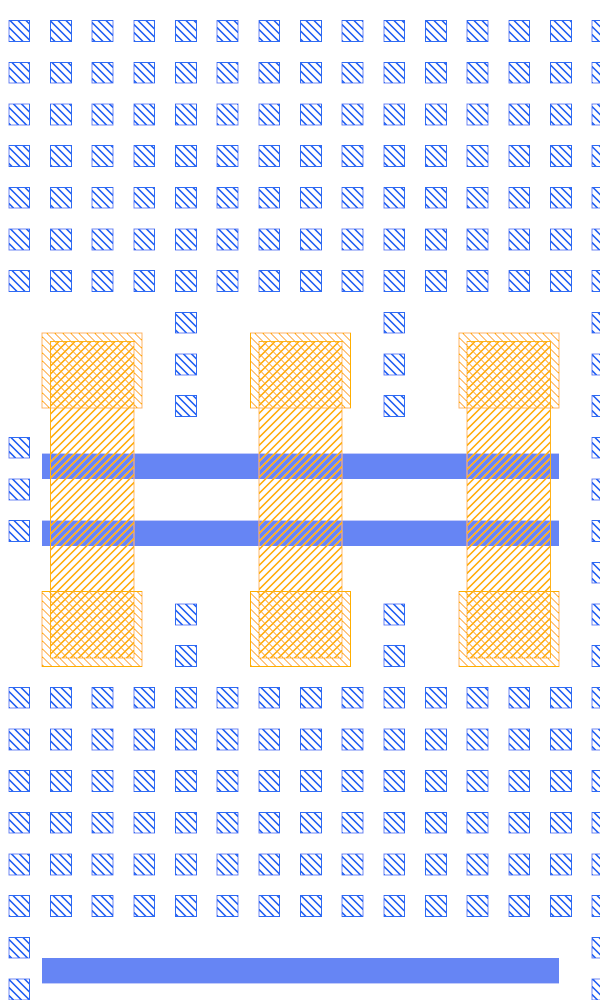

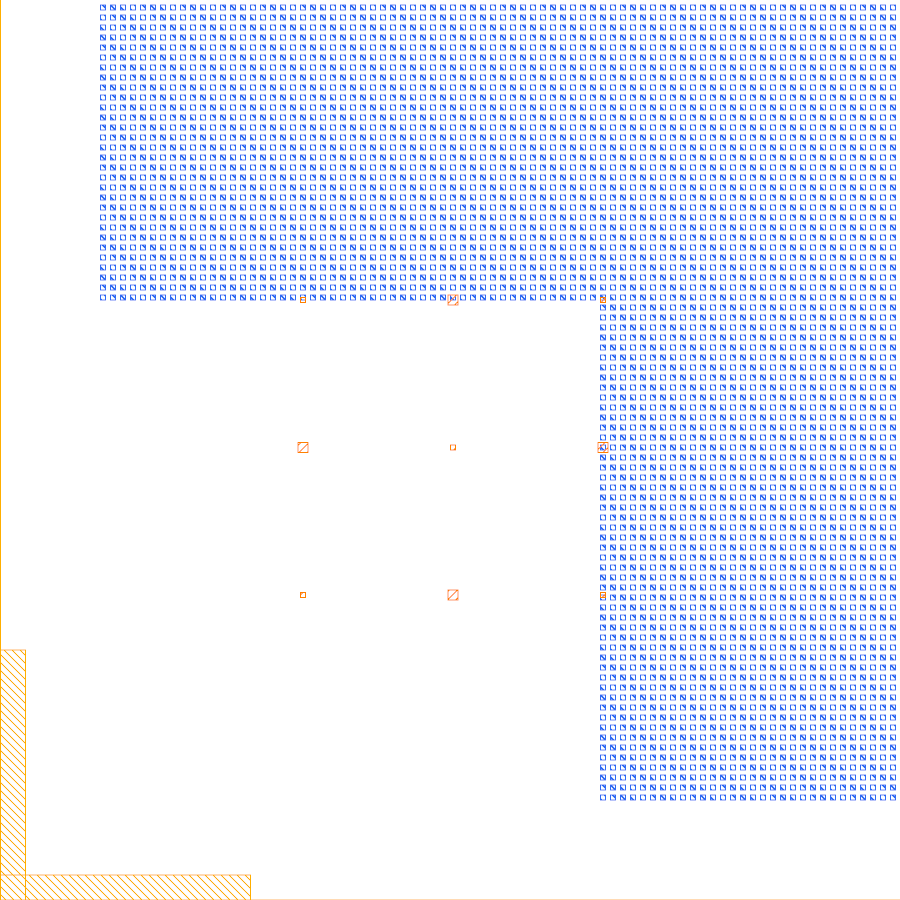

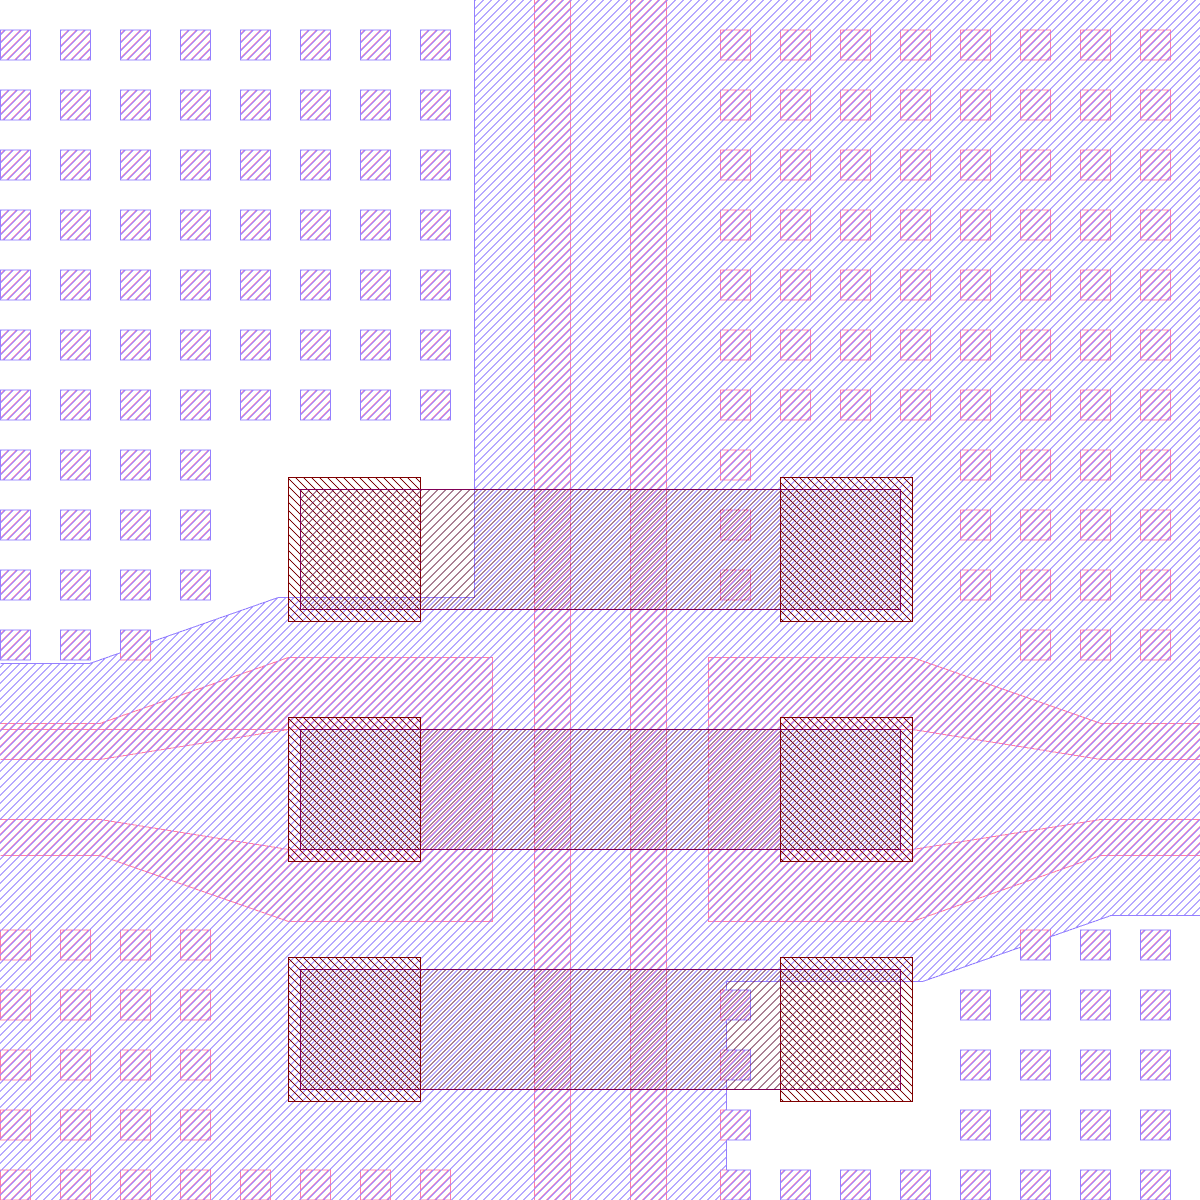

In [13]:
show_snapshot(d, OUT / "airbridge_crossings.png", box=(-100, -100, 10100, 10100))
show_snapshot(d, OUT / "airbridge_crossings_crossing.png", box=(2450, 6650, 3150, 7350), width=420)
show_snapshot(d, OUT / "airbridge_crossings_array.png", box=(3300, 7050, 6600, 7550), size=(1600, 250), width=640)
show_snapshot(d, OUT / "airbridge_crossings_bridge.png", box=(3530, 7180, 3670, 7420), size=(600, 1000), width=180)
show_snapshot(d, OUT / "airbridge_crossings_frame.png", box=(0, 0, 900, 900), size=(900, 900), width=300)
snap_file(Path("build") / "airbridge_crossings_fab.oas", OUT / "airbridge_crossings_fab.png", box=(2700, 6900, 2900, 7100), size=(1200, 1200), width=420);

**Reference: XOR with the source.** KQC's chip built stand-alone, XOR-ed layer by layer with this build (the union
of both layer sets; `refpoints`, `ports` and the `instance_names` label layer are annotation and are skipped). The
reference gets `name_brand="QC"`; with KQC's default "IQM" the frame text adds its area (last line). The column
"> 1 nm" is the XOR shrunk by one database unit. **The rebuild is expected to differ** by design: the frame (KQC's
ChipFrame vs the Quantcore die frame), the ground grid (KQC's stand-alone build has none) and the launchers with their lines' first legs (80 µm deeper here). A reference, not a pass/fail check.

In [14]:
import klayout.db as kdb
from kqcircuits.chips.airbridge_crossings import AirbridgeCrossings as KqcChip


def xor_vs_kqc(**ref_params):
    ref = pya.Layout()
    ref_top = ref.create_cell("ref")
    ref_top.insert(pya.DCellInstArray(KqcChip.create(ref, **ref_params).cell_index(), pya.DTrans()))
    ly = kdb.Layout()
    ly.read(str(d.out))
    top = ly.top_cell()
    mine = {ly.get_info(i).name: i for i in ly.layer_indexes()}
    theirs = {ref.get_info(i).name: i for i in ref.layer_indexes()}
    rows = []
    for name in sorted(set(mine) | set(theirs)):
        if not name or name in ("refpoints", "instance_names", "ports"):
            continue
        a = kdb.Region(ref_top.begin_shapes_rec(theirs[name])).merged() if name in theirs else kdb.Region()
        b = kdb.Region(top.begin_shapes_rec(mine[name])).merged() if name in mine else kdb.Region()
        if a.is_empty() and b.is_empty():
            continue
        x = a ^ b
        rows.append((name, x.area() * ref.dbu ** 2, x.sized(-1).area() * ref.dbu ** 2,
                     None if x.is_empty() else x.bbox().to_dtype(ref.dbu)))
    return rows


rows = xor_vs_kqc(name_brand="QC")
table = ["| layer | XOR area (µm²) | > 1 nm (µm²) | where |", "|---|---|---|---|"]
table += [f"| {n} | {x:.3g} | {y:.3g} | {w or ''} |" for n, x, y, w in rows]
total, real = sum(r[1] for r in rows), sum(r[2] for r in rows)
iqm = sum(r[1] for r in xor_vs_kqc())
display(Markdown("\n".join(table) + f"\n\n**Total XOR area: {total:.3g} µm²** ({real:.3g} µm² wider than 1 nm). "
                 f"Against KQC's default brand text \"IQM\": {iqm:.3g} µm²."))

| layer | XOR area (µm²) | > 1 nm (µm²) | where |
|---|---|---|---|
| 1t1_airbridge_flyover | 2.81e+05 | 2.81e+05 | (788,788;9212,9212) |
| 1t1_airbridge_pads | 5.4e+05 | 5.4e+05 | (788,788;9212,9212) |
| 1t1_base_metal_gap_for_EBL | 8.6e+06 | 8.6e+06 | (0,0;10000,10000) |
| 1t1_base_metal_gap_wo_grid | 8.79e+06 | 8.79e+06 | (0,0;10000,10000) |
| 1t1_chip_dicing | 2.68e+05 | 2.68e+05 | (-5,-5;10005,10005) |
| 1t1_ground_grid | 2.02e+07 | 2.01e+07 | (100,100;9895,9895) |
| 1t1_ground_grid_avoidance | 1.33e+07 | 1.33e+07 | (-5,-5;10005,10005) |
| 1t1_waveguide_path | 6.4e+03 | 6.4e+03 | (800,800;9200,9200) |
| qcc_chip_boundary | 1e+08 | 1e+08 | (0,0;10000,10000) |
| qcc_marker_0 | 4.75e+04 | 4.75e+04 | (0,0;10000,10000) |
| qcc_marker_1 | 2.1e+03 | 2.1e+03 | (297.5,300;9702.5,9700) |

**Total XOR area: 1.52e+08 µm²** (1.52e+08 µm² wider than 1 nm). Against KQC's default brand text "IQM": 1.52e+08 µm².

**Here:** the XOR (1.5 × 10⁸ µm²) is all from the expected differences: the qcc frame layers (the boundary layer alone 1 × 10⁸ µm²), the ground grid (2.0 × 10⁷ µm²) and its avoidance, KQC's frame (EBL, dicing and airbridge-marker layers) and the launcher shift (waveguide path 6.4 × 10³ µm²). The 1340 bridges and the 608 stubs add nothing on the airbridge layers beyond KQC's frame markers (the same 2.81 / 5.4 × 10⁵ µm² as on every test chip here).

## 15 · Summary

| | |
|---|---|
| **matches the source** | KQC's cells with their parameters, positions and paths; KQC's whole-area ground grid |
| **differs (PDK)** | the Quantcore die frame instead of KQC's ChipFrame; the launchers 80 µm further in (outer etch 100 µm, `frame.pad_edge`) with the lines' first legs; sapphire |
| **PDK design warnings** | as listed in step 7 |
| **FEM** | no sim groups, no jobs |